<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding Outliers**


Estimated time needed: **30** minutes


In this lab, you will work with a cleaned dataset to perform exploratory data analysis or EDA. 
You will explore the distribution of key variables and focus on identifying outliers in this lab.


## Objectives


In this lab, you will perform the following:


-  Analyze the distribution of key variables in the dataset.

-  Identify and remove outliers using statistical methods.

-  Perform relevant statistical and correlation analysis.


#### Install and import the required libraries


In [1]:
!pip install pandas
!pip install matplotlib
!pip install seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

<h3>Step 1: Load and Explore the Dataset</h3>


Load the dataset into a DataFrame and examine the structure of the data.


In [2]:
file_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv"

#Create the dataframe
df = pd.read_csv(file_url)

#Display the top 10 records
df.head()


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


<h3>Step 2: Plot the Distribution of Industry</h3>


Explore how respondents are distributed across different industries.

- Plot a bar chart to visualize the distribution of respondents by industry.

- Highlight any notable trends.


Industry
NaN                                           36579
Software Development                          11918
Other:                                         3077
Fintech                                        1641
Internet, Telecomm or Information Services     1629
Banking/Financial Services                     1371
Healthcare                                     1277
Manufacturing                                  1265
Retail and Consumer Services                   1264
Government                                      962
Media & Advertising Services                    894
Higher Education                                890
Transportation, or Supply Chain                 859
Computer Systems Design and Services            844
Energy                                          578
Insurance                                       389
Name: count, dtype: int64


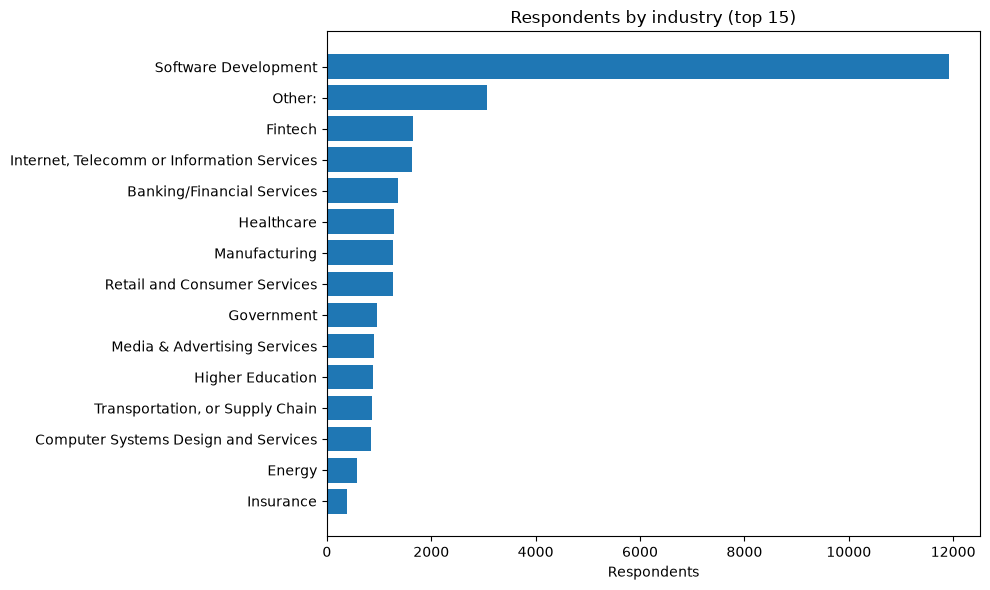

In [3]:
print(df['Industry'].value_counts(dropna=False))

industry = df['Industry'].value_counts().head(15)
plt.figure(figsize=(10, 6))
plt.barh(industry.index.tolist(), industry.values.tolist())
plt.gca().invert_yaxis()
plt.xlabel('Respondents')
plt.title('Respondents by industry (top 15)')
plt.tight_layout()
plt.show()

<h3>Step 3: Identify High Compensation Outliers</h3>


Identify respondents with extremely high yearly compensation.

- Calculate basic statistics (mean, median, and standard deviation) for `ConvertedCompYearly`.

- Identify compensation values exceeding a defined threshold (e.g., 3 standard deviations above the mean).


In [4]:
comp = df['ConvertedCompYearly']

mean, median, std = comp.mean(), comp.median(), comp.std()
print(f"Mean: {mean:,.0f}\nMedian: {median:,.0f}\nStd: {std:,.0f}")

threshold = mean + 3 * std
high = df[comp > threshold]
print(f"Threshold (mean + 3*std): {threshold:,.0f}")
print("Respondents above threshold:", len(high))
print(high['ConvertedCompYearly'].sort_values(ascending=False).head(10))

Mean: 86,155
Median: 65,000
Std: 186,757
Threshold (mean + 3*std): 646,426
Respondents above threshold: 89
15837    16256603.0
12723    13818022.0
28379     9000000.0
17593     6340564.0
17672     4936778.0
19267     3367716.0
23694     2584118.0
33720     2237846.0
34523     2153432.0
13763     2048046.0
Name: ConvertedCompYearly, dtype: float64


<h3>Step 4: Detect Outliers in Compensation</h3>


Identify outliers in the `ConvertedCompYearly` column using the IQR method.

- Calculate the Interquartile Range (IQR).

- Determine the upper and lower bounds for outliers.

- Count and visualize outliers using a box plot.


Q1: 32,712  Q3: 107,972  IQR: 75,260
Lower bound: -80,177  Upper bound: 220,861
Number of outliers: 978


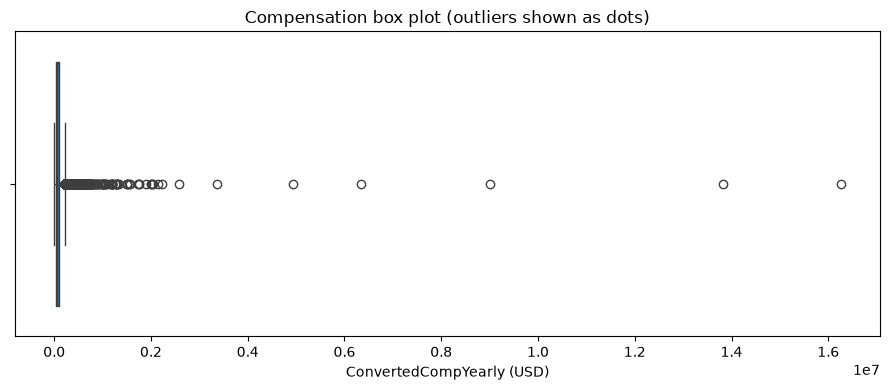

In [5]:
Q1 = comp.quantile(0.25)
Q3 = comp.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print(f"Q1: {Q1:,.0f}  Q3: {Q3:,.0f}  IQR: {IQR:,.0f}")
print(f"Lower bound: {lower:,.0f}  Upper bound: {upper:,.0f}")

outliers = df[(comp < lower) | (comp > upper)]
print("Number of outliers:", len(outliers))

plt.figure(figsize=(9, 4))
sns.boxplot(x=comp.dropna())
plt.xlabel('ConvertedCompYearly (USD)')
plt.title('Compensation box plot (outliers shown as dots)')
plt.tight_layout()
plt.show()

<h3>Step 5: Remove Outliers and Create a New DataFrame</h3>


Remove outliers from the dataset.

- Create a new DataFrame excluding rows with outliers in `ConvertedCompYearly`.
- Validate the size of the new DataFrame.


In [6]:
df_no_outliers = df[(comp >= lower) & (comp <= upper)].copy()

print("Original rows:", df.shape[0])
print("Rows after removing outliers:", df_no_outliers.shape[0])
print("Rows removed:", df.shape[0] - df_no_outliers.shape[0])
print(df_no_outliers['ConvertedCompYearly'].describe())

Original rows: 65437
Rows after removing outliers: 22457
Rows removed: 42980
count     22457.000000
mean      71347.201897
std       51271.396445
min           1.000000
25%       32000.000000
50%       63694.000000
75%      101281.000000
max      220207.000000
Name: ConvertedCompYearly, dtype: float64


<h3>Step 6: Correlation Analysis</h3>


Analyze the correlation between `Age` (transformed) and other numerical columns.

- Map the `Age` column to approximate numeric values.

- Compute correlations between `Age` and other numeric variables.

- Visualize the correlation matrix.


Age_numeric            1.000000
WorkExp                0.844999
YearsCodePro           0.822322
ConvertedCompYearly    0.369810
JobSat                 0.067124
Name: Age_numeric, dtype: float64


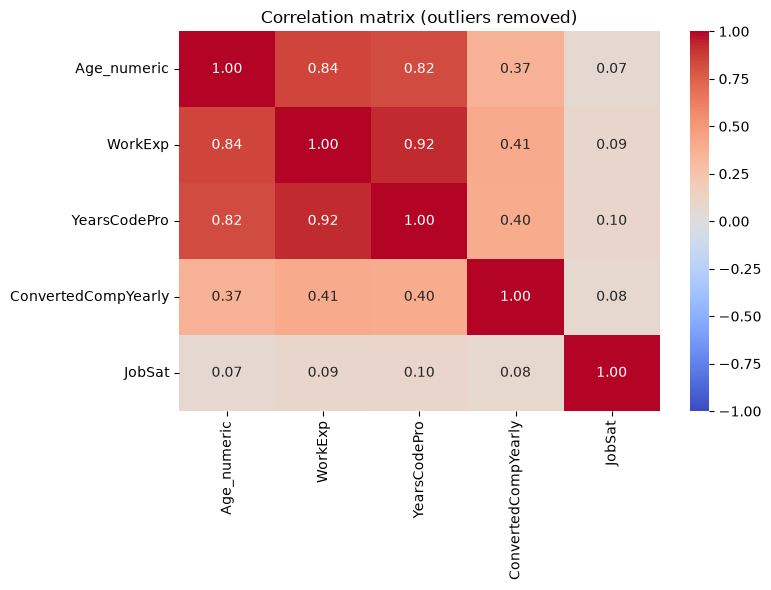

In [7]:
# 1. Map Age text to approximate numbers (midpoints of each range)
age_map = {
    'Under 18 years old': 16,
    '18-24 years old': 21,
    '25-34 years old': 29.5,
    '35-44 years old': 39.5,
    '45-54 years old': 49.5,
    '55-64 years old': 59.5,
    '65 years or older': 70,
}
df_no_outliers['Age_numeric'] = df_no_outliers['Age'].map(age_map)   # "Prefer not to say" becomes NaN

# YearsCodePro is text, so convert it too
df_no_outliers['YearsCodePro'] = pd.to_numeric(
    df_no_outliers['YearsCodePro'].replace({'Less than 1 year': 0.5, 'More than 50 years': 51}),
    errors='coerce')

# 2. Correlations of Age with the other numeric columns
num_cols = ['Age_numeric', 'WorkExp', 'YearsCodePro', 'ConvertedCompYearly', 'JobSat']
corr = df_no_outliers[num_cols].apply(pd.to_numeric, errors='coerce').corr()
print(corr['Age_numeric'].sort_values(ascending=False))

# 3. Visualize the correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix (outliers removed)')
plt.tight_layout()
plt.show()

<h3> Summary </h3>


In [9]:
The mean compensation is far above the median, so a few extreme salaries distort the average. The 3-standard-deviation rule and the IQR method flag different numbers of outliers, because the IQR method is more sensitive on skewed data. I removed the IQR outliers to get a more representative distribution. Age correlates strongly with years of experience, as expected, and only weakly with compensation and job satisfaction.

SyntaxError: invalid syntax (2549233455.py, line 1)

In this lab, you developed essential skills in **Exploratory Data Analysis (EDA)** with a focus on outlier detection and removal. Specifically, you:


- Loaded and explored the dataset to understand its structure.

- Analyzed the distribution of respondents across industries.

- Identified and removed high compensation outliers using statistical thresholds and the Interquartile Range (IQR) method.

- Performed correlation analysis, including transforming the `Age` column into numeric values for better analysis.


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-1|1.1|Madhusudan Moole|Reviewed and updated lab|                                                                                    
|2024-09-29|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
